In [1]:

# Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Load Cleaned Retail Dataset

df = pd.read_csv("../dataset/online_retail_II_cleaned.csv")

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["Customer ID"] = pd.to_numeric(
    df["Customer ID"], errors="coerce"
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset Shape: (1027017, 11)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Is_Cancelled,Is_Return,Sales
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,False,30.0


In [3]:

# Prepare Sales Transactions

df["Is_Cancelled"] = df["Is_Cancelled"].astype(bool)
df["Is_Return"] = df["Is_Return"].astype(bool)

sales_df = df[
    (~df["Is_Cancelled"]) &
    (~df["Is_Return"]) &
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
].copy()

returns_df = df[df["Is_Return"]].copy()

cancelled_df = df[df["Is_Cancelled"]].copy()

print("Normal Sales Transactions:", len(sales_df))
print("Returned Transactions:", len(returns_df))
print("Cancelled Transactions:", len(cancelled_df))

print("\nTotal Normal Sales Revenue:",
      round(sales_df["Sales"].sum(), 2))


Normal Sales Transactions: 1007913
Returned Transactions: 19103
Cancelled Transactions: 19104

Total Normal Sales Revenue: 20476260.45


In [4]:

# Overall Business Performance

total_revenue = sales_df["Sales"].sum()

total_orders = sales_df["Invoice"].nunique()

total_customers = sales_df["Customer ID"].nunique()

total_products = sales_df["StockCode"].nunique()

average_order_value = total_revenue / total_orders if total_orders else 0

print("=" * 50)
print("OVERALL BUSINESS PERFORMANCE")
print("=" * 50)

print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Products:", total_products)
print("Average Order Value:", round(average_order_value, 2))

print("=" * 50)


OVERALL BUSINESS PERFORMANCE
Total Revenue: 20476260.45
Total Orders: 40077
Total Customers: 5878
Total Products: 4917
Average Order Value: 510.92


Year-wise Revenue:
Year
2009     822483.950
2010    9833100.424
2011    9820676.074
Name: Sales, dtype: float64


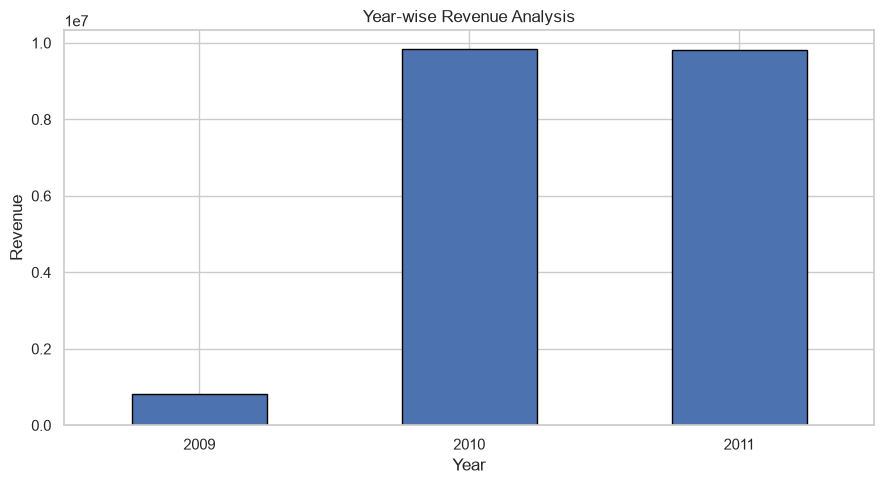

In [5]:

# Year-wise Revenue Analysis

sales_df["Year"] = sales_df["InvoiceDate"].dt.year

yearly_revenue = sales_df.groupby("Year")["Sales"].sum()

print("Year-wise Revenue:")
print(yearly_revenue)

plt.figure(figsize=(9, 5))

yearly_revenue.plot(kind="bar", edgecolor="black")

plt.title("Year-wise Revenue Analysis")
plt.xlabel("Year")
plt.ylabel("Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


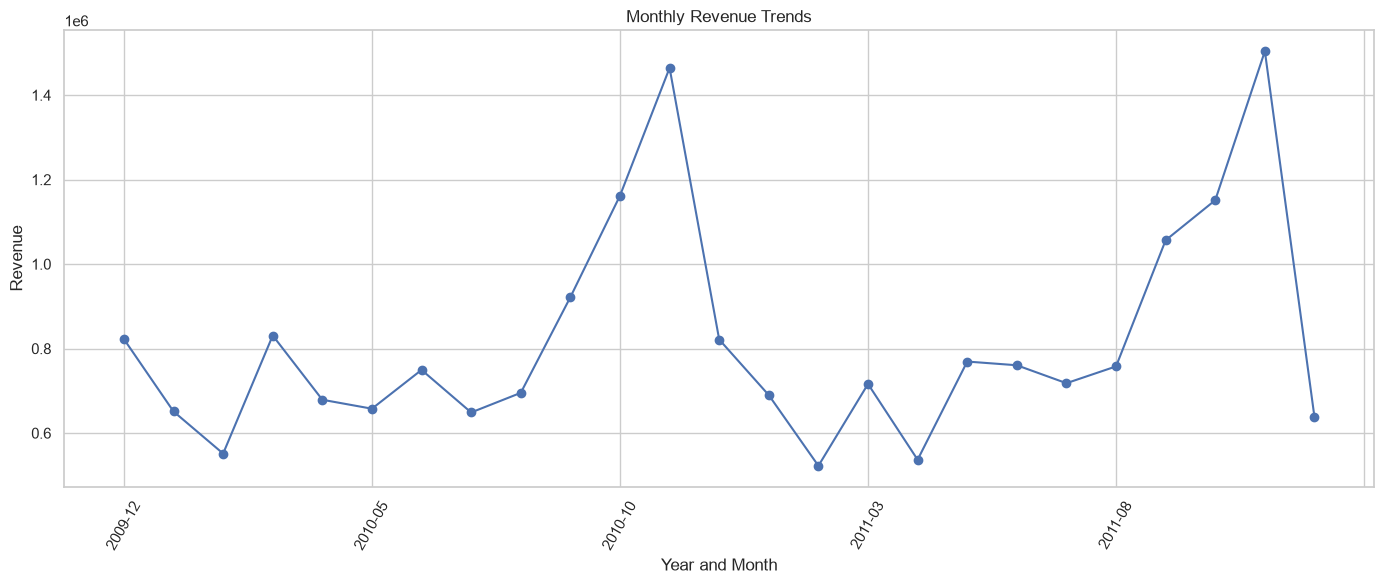

Monthly Revenue:
YearMonth
2009-12     822483.950
2010-01     651155.112
2010-02     551504.726
2010-03     830915.261
2010-04     678875.252
2010-05     657705.500
2010-06     749537.310
2010-07     648810.270
2010-08     695251.910
2010-09     921696.991
2010-10    1161902.220
2010-11    1464293.142
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637808.330
Name: Sales, dtype: float64


In [6]:

# Monthly Revenue Trends

sales_df["YearMonth"] = (
    sales_df["InvoiceDate"].dt.to_period("M").astype(str)
)

monthly_revenue = (
    sales_df.groupby("YearMonth")["Sales"].sum()
)

plt.figure(figsize=(14, 6))

monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Revenue Trends")
plt.xlabel("Year and Month")
plt.ylabel("Revenue")
plt.xticks(rotation=60)
plt.grid(True)
plt.tight_layout()
plt.show()

print("Monthly Revenue:")
print(monthly_revenue)


Top 10 Products:
Description
Manual                                339241.29
REGENCY CAKESTAND 3 TIER              330590.32
DOTCOM POSTAGE                        309854.11
WHITE HANGING HEART T-LIGHT HOLDER    260990.22
PAPER CRAFT , LITTLE BIRDIE           168469.60
PARTY BUNTING                         148318.28
JUMBO BAG RED RETROSPOT               148073.47
ASSORTED COLOUR BIRD ORNAMENT         129324.49
POSTAGE                               125682.42
PAPER CHAIN KIT 50'S CHRISTMAS        117760.29
Name: Sales, dtype: float64


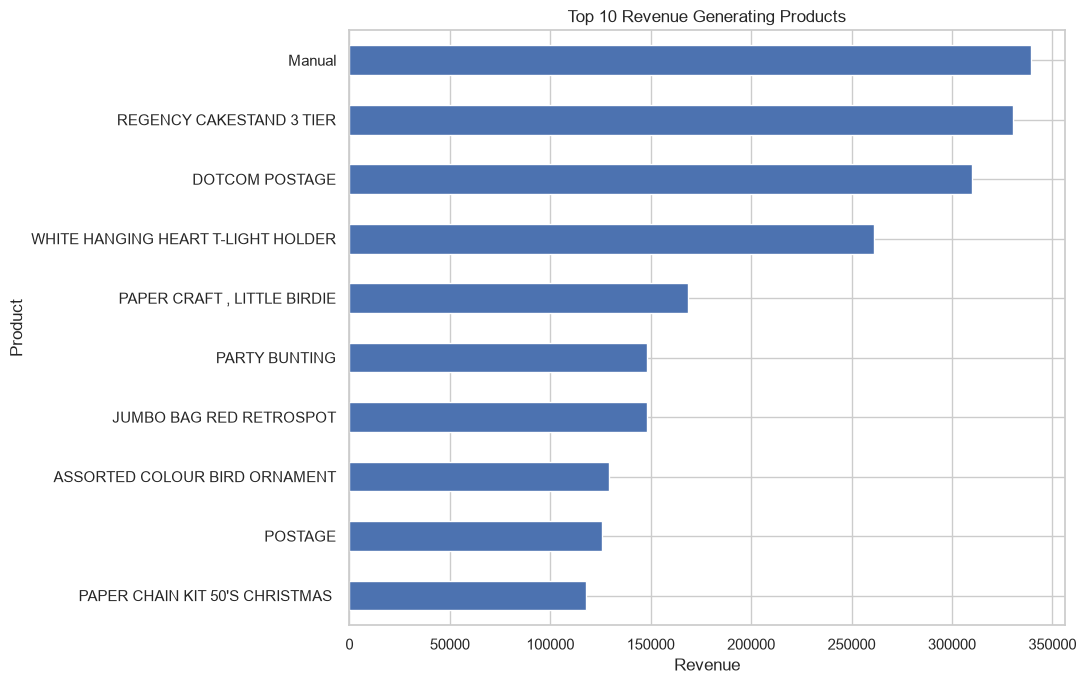

In [7]:

# Top 10 Revenue Generating Products

top_products = (
    sales_df.groupby("Description")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products:")
print(top_products)

plt.figure(figsize=(11, 7))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Revenue Generating Products")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


Top 10 Countries by Revenue:
Country
United Kingdom    1.741020e+07
EIRE              6.587673e+05
Netherlands       5.540381e+05
Germany           4.250197e+05
France            3.504561e+05
Australia         1.692835e+05
Spain             1.083325e+05
Switzerland       1.006856e+05
Sweden            9.186982e+04
Denmark           6.858069e+04
Name: Sales, dtype: float64


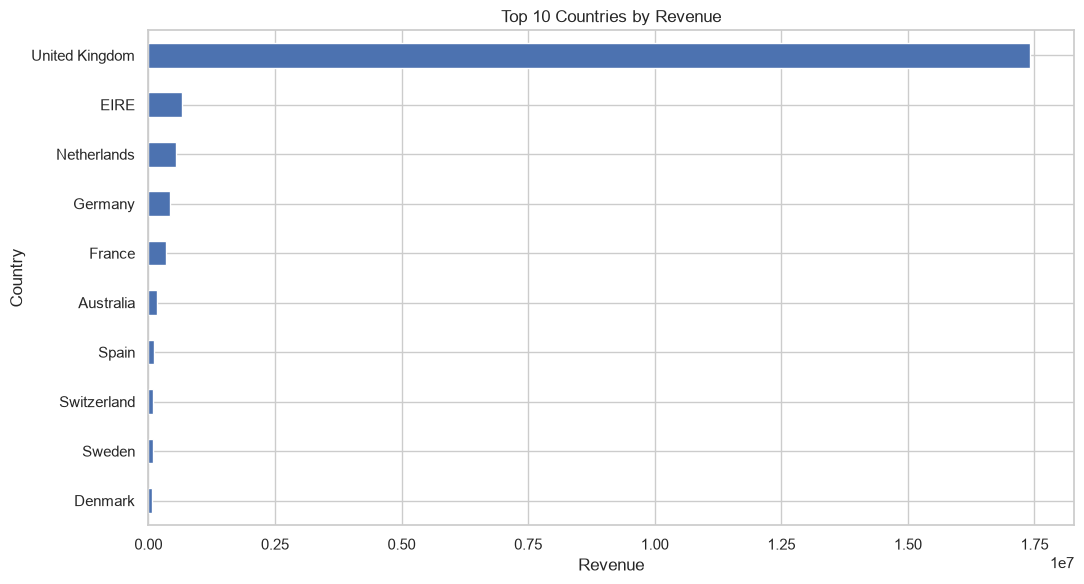

In [8]:

# Country-wise Revenue Analysis

country_revenue = (
    sales_df.groupby("Country")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

top_countries = country_revenue.head(10)

print("Top 10 Countries by Revenue:")
print(top_countries)

plt.figure(figsize=(11, 6))

top_countries.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


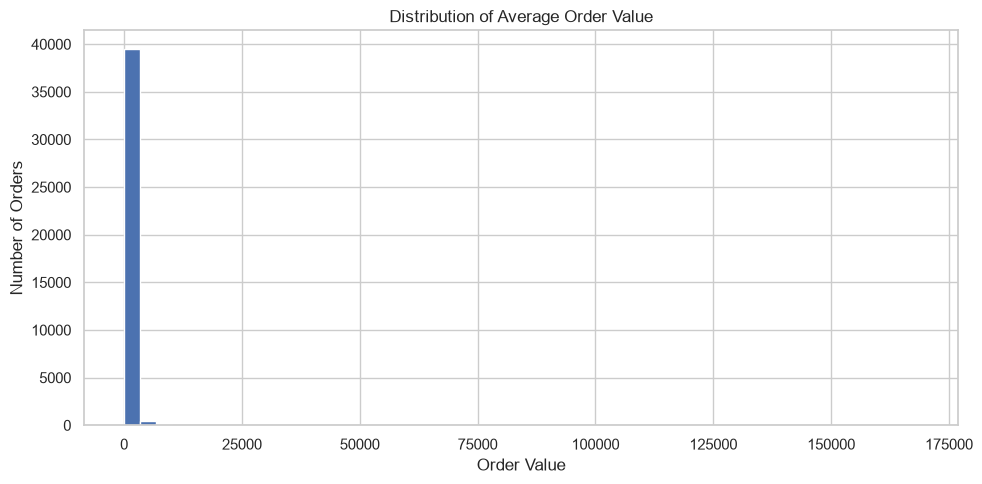

In [9]:
# Average Order Value (AOV) Analysis

invoice_revenue = (
    sales_df.groupby("Invoice")["Sales"].sum()
)

plt.figure(figsize=(10, 5))
invoice_revenue.hist(bins=50)
plt.title("Distribution of Average Order Value")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

Total Orders: 40077
Average Order Value: 510.92
Highest Order Value: 168469.6
Lowest Order Value: 0.19


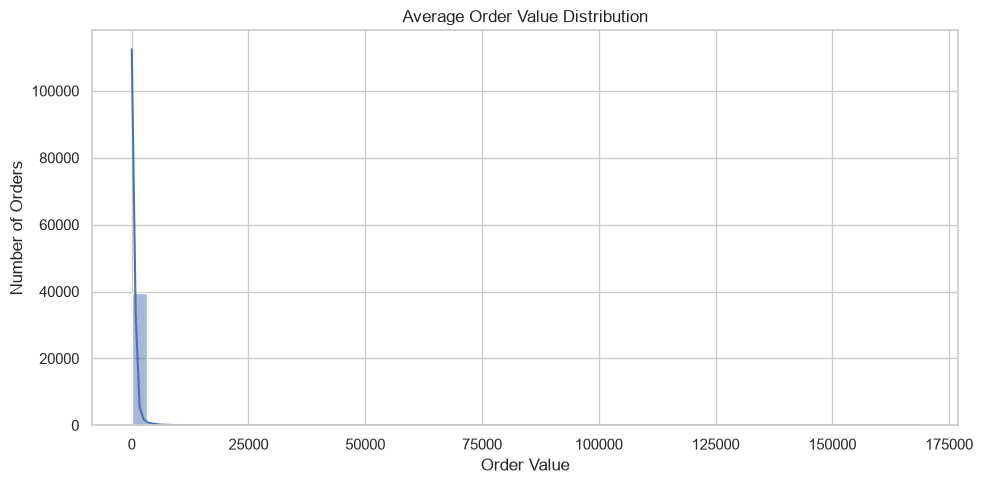

In [10]:

# Calculate Average Order Value

order_revenue = sales_df.groupby("Invoice")["Sales"].sum()

aov = order_revenue.mean()

print("Total Orders:", len(order_revenue))
print("Average Order Value:", round(aov, 2))
print("Highest Order Value:", round(order_revenue.max(), 2))
print("Lowest Order Value:", round(order_revenue.min(), 2))

plt.figure(figsize=(10, 5))

sns.histplot(order_revenue, bins=50, kde=True)

plt.title("Average Order Value Distribution")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()


Total Identified Customers: 5878
Repeat Customers: 4255
One-Time Customers: 1623
Repeat Customer Percentage: 72.39 %


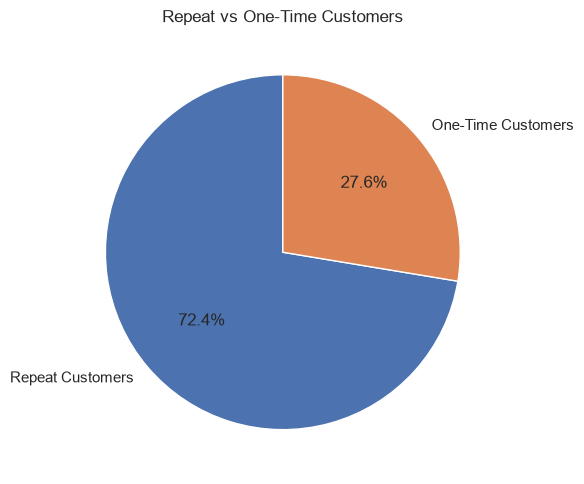

In [11]:

# Repeat Customer Analysis

customer_orders = (
    sales_df.dropna(subset=["Customer ID"])
    .groupby("Customer ID")["Invoice"]
    .nunique()
)

repeat_customers = (customer_orders > 1).sum()
one_time_customers = (customer_orders == 1).sum()

total_identified_customers = len(customer_orders)

repeat_percentage = (
    repeat_customers / total_identified_customers * 100
    if total_identified_customers else 0
)

print("Total Identified Customers:", total_identified_customers)
print("Repeat Customers:", repeat_customers)
print("One-Time Customers:", one_time_customers)
print("Repeat Customer Percentage:", round(repeat_percentage, 2), "%")

plt.figure(figsize=(7, 5))

pd.Series({
    "Repeat Customers": repeat_customers,
    "One-Time Customers": one_time_customers
}).plot(kind="pie", autopct="%1.1f%%", startangle=90)

plt.title("Repeat vs One-Time Customers")
plt.ylabel("")
plt.tight_layout()
plt.show()


Total Return Records: 19103
Total Return Value: 1462424.18

Total Cancelled Records: 19104
Total Cancelled Value: 1462050.61


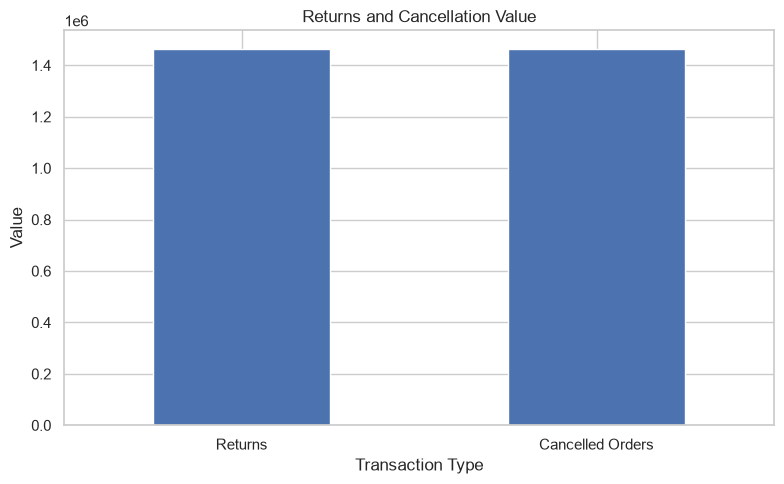

In [12]:

# Returns and Cancellation Analysis

return_value = abs(returns_df["Sales"].sum())

cancelled_value = abs(cancelled_df["Sales"].sum())

print("Total Return Records:", len(returns_df))
print("Total Return Value:", round(return_value, 2))

print("\nTotal Cancelled Records:", len(cancelled_df))
print("Total Cancelled Value:", round(cancelled_value, 2))

plt.figure(figsize=(8, 5))

pd.Series({
    "Returns": return_value,
    "Cancelled Orders": cancelled_value
}).plot(kind="bar")

plt.title("Returns and Cancellation Value")
plt.xlabel("Transaction Type")
plt.ylabel("Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Day_Name
Monday       3581594.176
Tuesday      4078149.962
Wednesday    3488444.333
Thursday     4195212.762
Friday       3323908.883
Saturday        9803.050
Sunday       1799147.282
Name: Sales, dtype: float64


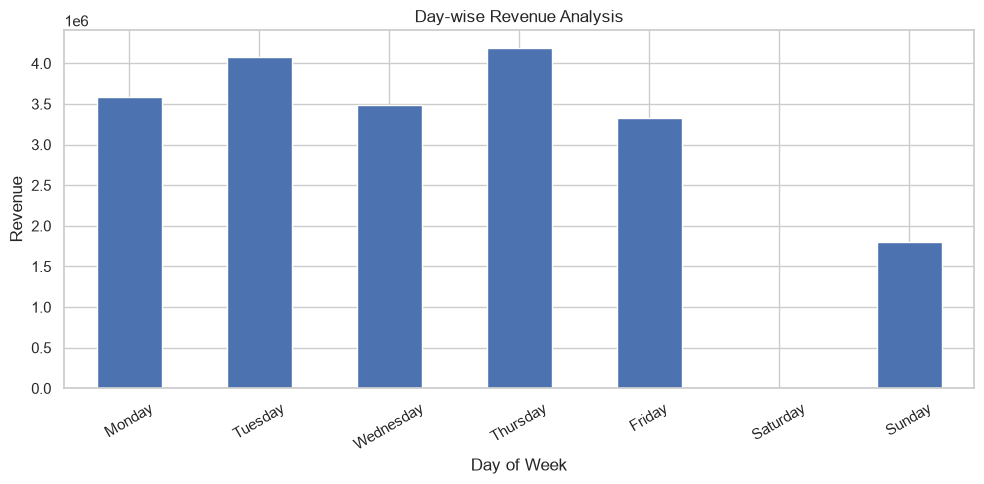

In [13]:

# Day-wise Revenue Analysis

sales_df["Day_Name"] = sales_df["InvoiceDate"].dt.day_name()

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

day_revenue = (
    sales_df.groupby("Day_Name")["Sales"]
    .sum()
    .reindex(day_order)
)

print(day_revenue)

plt.figure(figsize=(10, 5))

day_revenue.plot(kind="bar")

plt.title("Day-wise Revenue Analysis")
plt.xlabel("Day of Week")
plt.ylabel("Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


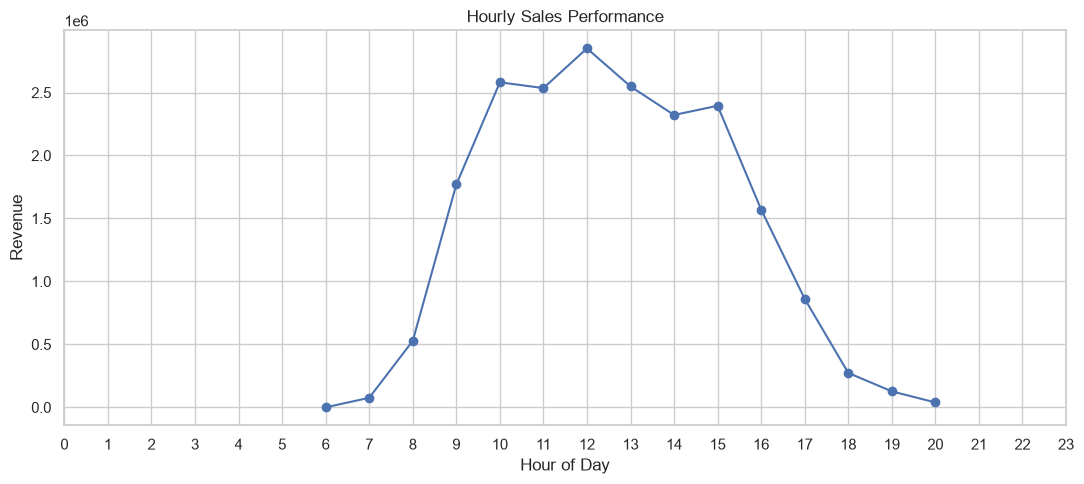

Hourly Revenue:
Hour
6           4.250
7       75765.570
8      528185.570
9     1769631.031
10    2581131.333
11    2535325.463
12    2850377.671
13    2548467.544
14    2321684.731
15    2394943.792
16    1570143.801
17     861460.132
18     273405.020
19     126830.350
20      38904.190
Name: Sales, dtype: float64


In [14]:

# Hourly Sales Analysis

sales_df["Hour"] = sales_df["InvoiceDate"].dt.hour

hourly_revenue = sales_df.groupby("Hour")["Sales"].sum()

plt.figure(figsize=(11, 5))

hourly_revenue.plot(kind="line", marker="o")

plt.title("Hourly Sales Performance")
plt.xlabel("Hour of Day")
plt.ylabel("Revenue")
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show()

print("Hourly Revenue:")
print(hourly_revenue)


In [18]:
print("=" * 60)
print("ADVANCED SALES ANALYSIS - BUSINESS INSIGHTS")
print("=" * 60)

# --- Robust Column Detection ---
# Automatically finds the correct customer column name if variations exist
customer_col = None
for col in ['CustomerID', 'Customer ID', 'customer_id', 'Customer', 'CustomerID_']:
    if col in df.columns:
        customer_col = col
        break

if customer_col is None:
    raise KeyError(f"Customer column not found. Your available columns are: {df.columns.tolist()}")

# Automatically finds or calculates the revenue/total price column
revenue_col = None
for col in ['TotalPrice', 'Revenue', 'Sales', 'Total', 'Amount']:
    if col in df.columns:
        revenue_col = col
        break

if revenue_col is None and 'Quantity' in df.columns and 'UnitPrice' in df.columns:
    df['TotalPrice'] = df['Quantity'] * df['UnitPrice']
    revenue_col = 'TotalPrice'

# Calculate top customers safely using the detected column names
top_customers = df.groupby(customer_col)[revenue_col].sum().sort_values(ascending=False)

# --- Print Insights ---
print("\n1. Total Revenue:")
print(round(total_revenue, 2))

print("\n2. Highest Revenue Generating Country:")
print(country_revenue.idxmax())

print("\n3. Best Revenue Generating Product:")
print(top_products.index[0])

print("\n4. Highest Revenue Generating Customer:")
print(top_customers.index[0])

print("\n5. Average Order Value:")
print(round(aov, 2))

print("\n6. Repeat Customer Percentage:")
print(round(repeat_percentage, 2), "%")

print("\n7. Highest Revenue Month:")
print(monthly_revenue.idxmax())

print("\n8. Highest Revenue Day:")
print(day_revenue.idxmax())

print("\nBusiness Insights Generated Successfully!")
print("=" * 60)

ADVANCED SALES ANALYSIS - BUSINESS INSIGHTS

1. Total Revenue:
20476260.45

2. Highest Revenue Generating Country:
United Kingdom

3. Best Revenue Generating Product:
Manual

4. Highest Revenue Generating Customer:
18102.0

5. Average Order Value:
510.92

6. Repeat Customer Percentage:
72.39 %

7. Highest Revenue Month:
2011-11

8. Highest Revenue Day:
Thursday

Business Insights Generated Successfully!


In [19]:

# Export Business Analysis Results

output_folder = Path("../dataset/business_analysis")
output_folder.mkdir(parents=True, exist_ok=True)

yearly_revenue.to_csv(output_folder / "yearly_revenue.csv")
monthly_revenue.to_csv(output_folder / "monthly_revenue.csv")
top_products.to_csv(output_folder / "top_products.csv")
top_countries.to_csv(output_folder / "top_countries.csv")
top_customers.to_csv(output_folder / "top_customers.csv")
cluster_summary = None  # Not used in this notebook

print("All Business Analysis Reports Exported!")
print("Output Folder:", output_folder.resolve())


All Business Analysis Reports Exported!
Output Folder: C:\Users\HP\OneDrive\Desktop\Customer-Shopping-Behavior-Analytics\dataset\business_analysis
